# Importing the libraries

**Explanation:** In this block I load every library I need: numpy and pandas for the data, KMeans and DBSCAN for clustering, StandardScaler for scaling, three metrics to evaluate the clusters, and matplotlib for the plots.

In [61]:
# Import all the libraries used in this notebook
import numpy as np
from sklearn.cluster import KMeans, DBSCAN
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

# Preprocessing on Dataset

**Explanation:** I read Customer.csv into a DataFrame and look at the first rows to understand the columns (CustomerID, Gender, Age, Annual Income, Spending Score).

In [62]:
# Load the dataset and take a first look at it
main_data_frame = pd.read_csv("Customer.csv")
main_data_frame.head() 

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Explanation:** I keep only the three numeric features I want to cluster on: Age, Annual Income and Spending Score. CustomerID is just an identifier. I removed Gender on purpose: after scaling it is a binary feature with two far-apart values, so it split the data into two big groups (men/women) and the real clusters were not found. I use .copy() so later changes never touch the main DataFrame.

In [63]:
# Select the clustering features by column name (no CustomerID, no Gender)
df = main_data_frame[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].copy()
df

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40
...,...,...,...
195,35,120,79
196,45,126,28
197,32,126,74
198,32,137,18


**Explanation:** I check each feature for missing values before modelling. All counts are 0, so no cleaning is needed.

In [64]:
# Count the NaN values in every feature
for title in df.columns:
    count = df[title].isna().sum()
    print(f"There are {count} number NaN in column {title}.")

There are 0 number NaN in column Age.
There are 0 number NaN in column Annual Income (k$).
There are 0 number NaN in column Spending Score (1-100).


**Explanation:** K-Means and DBSCAN are distance-based, so features with bigger ranges (like income) would dominate the others. I standardise the features (mean 0, std 1). I keep the scaler object in a variable because I need it later to convert the cluster centers back to the original units.

In [65]:
# Standardise the features and keep the scaler for inverse_transform
scaler = StandardScaler()
normalize_data_set = scaler.fit_transform(df)
normalize_data_set.shape

(200, 3)

**Explanation:** This function evaluates any clustering result in the same way, so I can compare K-Means, DBSCAN and Hierarchical later. It ignores noise points (label -1, only DBSCAN produces them), reports the noise ratio and number of clusters, and calculates Silhouette (higher is better), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better). The scores are only calculated when there are at least 2 clusters, because they are undefined otherwise.

In [66]:
# Evaluate a clustering result: noise ratio + 3 internal metrics
def evaluate_clustering_model (scaled_dataset: np.ndarray, labels: np.ndarray) -> dict:
    mask                = labels != -1
    scaled_dataset_used = scaled_dataset[mask] 
    labels_used         = labels[mask]
    n_cluster           = len(set(labels_used))
    
    result = {"clusters number"        : n_cluster,
              "noise ratio"            : float(np.mean(labels == -1)),
              "Silhouette Score"       : None,
              "Davies_Bouldin Score"   : None,
              "Calinski_Harabasz Score": None}

    if 2 <= n_cluster:
        result["Silhouette Score"]        = silhouette_score(scaled_dataset_used, labels_used)
        result["Davies_Bouldin Score"]    = davies_bouldin_score(scaled_dataset_used, labels_used)
        result["Calinski_Harabasz Score"] = calinski_harabasz_score(scaled_dataset_used, labels_used)

    return result

# Implementing the models
## 1) K-Means Model

**Explanation:** I train K-Means for K = 2..12. For each K I fit the model once, store it, store its inertia (for the elbow plot) and store its evaluation scores. n_init=12 and random_state=3 make the result stable and reproducible. results[3] shows the scores of K=5 (index 3 = K 2+3).

In [70]:
# Train K-Means for different K values and collect inertia + metrics
cluster_numbers = list(range(2, 13))
KMeans_models   = [] 
results         = []
inertias        = []
for cluster_number in cluster_numbers:
    kmeans_model = KMeans(init="k-means++", n_clusters=cluster_number, n_init=12, random_state=3).fit(normalize_data_set)
    KMeans_models.append(kmeans_model)
    inertias.append(kmeans_model.inertia_)
    results.append(evaluate_clustering_model(scaled_dataset=normalize_data_set, labels=kmeans_model.labels_))

results[3]

{'clusters number': 5,
 'noise ratio': 0.0,
 'Silhouette Score': 0.41664341513732767,
 'Davies_Bouldin Score': 0.874551051002418,
 'Calinski_Harabasz Score': 125.10094020060956}

**Explanation:** This helper picks the best model for a given metric. It knows the direction of each metric (max for Silhouette and Calinski-Harabasz, min for Davies-Bouldin), skips results without a score and validates the inputs. I print the winner for all three metrics. They do not agree: Silhouette prefers K=6, Davies-Bouldin prefers K=7, and Calinski-Harabasz grows with K, so it is not reliable alone for choosing K.

In [71]:
# Helper to choose the best model by a metric + compare the three metrics
def choosing_best_model(models: list[KMeans | DBSCAN], results: list[dict], metric: str):
    metric_direction = {
        "Silhouette Score": True,
        "Davies_Bouldin Score": False,
        "Calinski_Harabasz Score": True
    } 

    if not results:
        raise ValueError("No evalution results are available.")

    if len(models) != len(results):
        raise ValueError("The number of models and results must match.")

    if metric not in metric_direction:
        raise ValueError(f"Unsupported metric: {metric}")

    valid_indeces = [index for index, result in enumerate(results) if result.get(metric) is not None and np.isfinite(result[metric])]

    if not valid_indeces:
        raise ValueError(f"No valid Score found for: {metric}")

    select_best = max if metric_direction[metric] else min
    best_index  = select_best(valid_indeces, key=lambda index: results[index][metric])
    return (best_index, results[best_index])

print(choosing_best_model(KMeans_models, results, "Silhouette Score"))
print(choosing_best_model(KMeans_models, results, "Davies_Bouldin Score"))
print(choosing_best_model(KMeans_models, results, "Calinski_Harabasz Score"))


(4, {'clusters number': 6, 'noise ratio': 0.0, 'Silhouette Score': 0.42742814991580175, 'Davies_Bouldin Score': 0.8277427938879608, 'Calinski_Harabasz Score': 135.10221697156993})
(5, {'clusters number': 7, 'noise ratio': 0.0, 'Silhouette Score': 0.4172318949549161, 'Davies_Bouldin Score': 0.7934668170964966, 'Calinski_Harabasz Score': 132.77430922888286})
(9, {'clusters number': 11, 'noise ratio': 0.0, 'Silhouette Score': 0.4115045142586146, 'Davies_Bouldin Score': 0.8464257236387936, 'Calinski_Harabasz Score': 138.78556180605307})


**Explanation:** Elbow plot: inertia (sum of squared distances to the nearest center) for each K. I look for the point where the decrease slows down. The elbow is around K=6-7, which matches the Silhouette result.

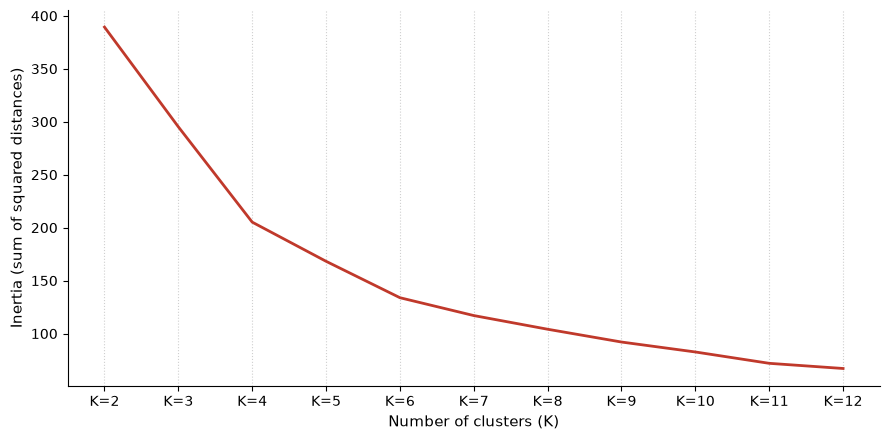

In [69]:
# Elbow plot
plt.figure(figsize=(9, 4.5))
plt.plot(cluster_numbers, inertias, color="#c0392b", linewidth=2)

plt.xticks(cluster_numbers, [f"K={k}" for k in cluster_numbers])
plt.xlabel("Number of clusters (K)", fontsize=11)
plt.ylabel("Inertia (sum of squared distances)", fontsize=11)

plt.grid(axis="x", linestyle=":", alpha=0.6)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Explanation:** I choose K=6 because it has the highest Silhouette, its Davies-Bouldin is very close to K=7, it has fewer clusters, and it is near the elbow. I save the labels in the main DataFrame and convert the centers back to the original units with the scaler, so I can read them (for example 'age 32, income 86k, score 82').

In [72]:
# Pick the final K-Means model, save labels, convert centers to original units
best_index, best_result = choosing_best_model(KMeans_models, results, "Silhouette Score")
k_means = KMeans_models[best_index]
labels = k_means.labels_
main_data_frame['Cluster_label'] = labels
centers_original = scaler.inverse_transform(k_means.cluster_centers_)
centers_df = pd.DataFrame(centers_original, columns=df.columns)
print(centers_df)
main_data_frame.head()

         Age  Annual Income (k$)  Spending Score (1-100)
0  56.333333           54.266667               49.066667
1  26.684211           57.578947               47.789474
2  41.939394           88.939394               16.969697
3  45.523810           26.285714               19.380952
4  32.692308           86.538462               82.128205
5  25.250000           25.833333               76.916667


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster_label
0,1,Male,19,15,39,5
1,2,Male,21,15,81,5
2,3,Female,20,16,6,3
3,4,Female,23,16,77,5
4,5,Female,31,17,40,3


In [73]:
main_data_frame['Cluster_label'] = labels
centers_original = scaler.inverse_transform(k_means.cluster_centers_)
centers_df = pd.DataFrame(centers_original, columns=df.columns)
print(centers_df)
main_data_frame.head()

         Age  Annual Income (k$)  Spending Score (1-100)
0  56.333333           54.266667               49.066667
1  26.684211           57.578947               47.789474
2  41.939394           88.939394               16.969697
3  45.523810           26.285714               19.380952
4  32.692308           86.538462               82.128205
5  25.250000           25.833333               76.916667


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster_label
0,1,Male,19,15,39,5
1,2,Male,21,15,81,5
2,3,Female,20,16,6,3
3,4,Female,23,16,77,5
4,5,Female,31,17,40,3


**Explanation:** 2D view of the clusters: x = income, y = spending score, color = cluster, point size = age. This pair of features shows the cluster structure best.

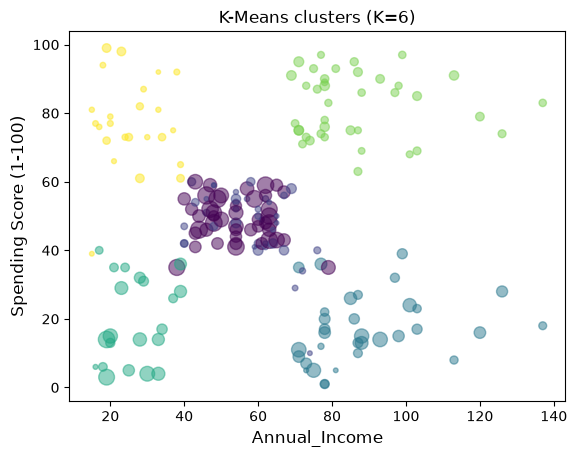

In [74]:
# NOTE (to fix): 'labels' is not defined in this notebook anymore. It should be k_means.labels_
# 2D scatter plot of the clusters (Income vs Score)
area = (np.pi * (df["Age"].astype(np.float64))**2)/100

plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], s=area, c=labels.astype(np.float64), alpha=0.5)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.xlabel('Annual_Income', fontsize=12)
plt.title('K-Means clusters (K=6)')
plt.show()

**Explanation:** 3D view with all three features (x = income, y = score, z = age). Centers are drawn as big X markers with black edges, using the same color as their cluster. depthshade=False keeps them visible. Axis labels are in the same order as the data.

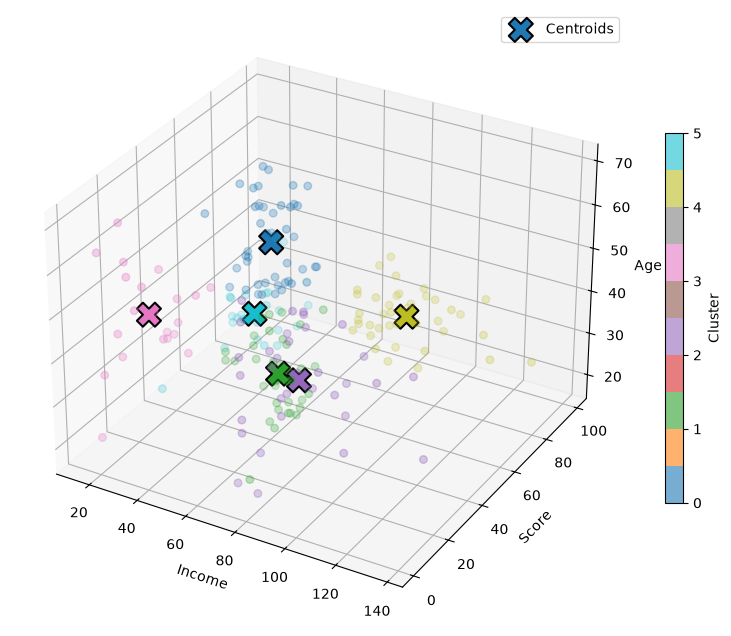

In [60]:
# 3D scatter plot of the clusters with their centers
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")

p = ax.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], df["Age"], c=k_means.labels_, cmap="tab10", alpha=0.6, s=30)
ax.scatter(centers_df["Annual Income (k$)"], centers_df["Spending Score (1-100)"], centers_df["Age"],
           c=range(len(centers_df)), cmap="tab10", marker="X", s=300,
           edgecolors="black", linewidths=1.5, depthshade=False, zorder=10, label="Centroids")

ax.set_xlabel("Income"); ax.set_ylabel("Score"); ax.set_zlabel("Age")
ax.legend()
fig.colorbar(p, ax=ax, shrink=0.6, label="Cluster")
plt.show()

**Explanation:** Cluster profile: the mean of Age, Income and Score for every cluster. This is what turns the clusters into customer segments. These means should match the centers above, because a K-Means center is the mean of its points.

In [14]:
# Cluster profile (mean of each feature per cluster)
profile = (main_data_frame
           .groupby("Cluster_label")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]
           .mean()
           .round(1))
profile

,Age,Annual Income (k$),Spending Score (1-100)
Cluster_label,,,
0,56.3,54.3,49.1
1,26.7,57.6,47.8
2,41.9,88.9,17.0
3,45.5,26.3,19.4
4,32.7,86.5,82.1
5,25.2,25.8,76.9


## 2) DBSCN Model

In [ ]:
eps_values         = np.linspace(0.1, 1, 10)
min_samples_values = list(range(3, 11, 1))
for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan_model = DBSCAN(eps=eps, min_samples=min_samples)

[3, 4, 5, 6, 7, 8, 9, 10]

In [50]:
DBSCAN_Model = DBSCAN(eps=0.4, min_samples=3).fit(normalize_data_set)
noise_samples_number = (DBSCAN_Model.labels_ == -1).sum()
DBSCAN_labels = DBSCAN_Model.labels_
print(f"The total number of dataset is: {normalize_data_set.shape[0]}")
print(f"The total of labels is: {DBSCAN_labels.shape[0]}")
print(f"The total number of noise samples is: {noise_samples_number}")
print(f"The number of cluster is: {len(set(DBSCAN_labels)) - (1 if -1 in DBSCAN_labels else 0)}")
DBSCAN_Model.labels_

The total number of dataset is: 200
The total of labels is: 200
The total number of noise samples is: 59
The number of cluster is: 10


array([-1,  0, -1,  0,  1,  0, -1, -1, -1,  2, -1, -1, -1,  0, -1,  0,  1,
       -1, -1, -1,  1,  0, -1,  2, -1,  2, -1, -1, -1,  0, -1,  0, -1, -1,
       -1,  0, -1,  2, -1,  0, -1, -1,  3,  4,  3, -1,  3,  4,  4,  4,  3,
        4,  4,  5,  3,  3,  3,  5,  4,  3,  5,  4,  5,  5,  5,  4,  3,  5,
        4,  4,  5,  3,  5,  5,  5,  4,  3,  3,  4,  3,  5,  3,  5,  3,  4,
        3,  5,  4,  3,  3,  5,  4,  3,  3, -1,  4,  3,  4,  3,  4,  4,  3,
        5,  4,  3,  4,  5,  3,  5,  5,  5,  4,  3,  4,  4,  4,  5,  3,  3,
        3,  4,  3, -1,  6,  8,  6, -1,  6, -1,  6,  7,  6,  8,  6,  9,  6,
        7,  6,  9,  6, -1,  6,  8,  6, -1,  6, -1,  6, -1,  6,  7,  6,  7,
        6,  7,  6, -1,  6, -1,  6, -1,  6,  9,  6, -1,  6,  7,  6, -1, -1,
        7,  6,  7,  6, -1,  6, -1,  6, -1,  6, -1,  6, -1,  6, -1,  6, -1,
       -1, -1,  6, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1])